In [33]:
#use packages and files

# import Pkg; Pkg.add("GLM")
println("test")
using LinearAlgebra
using SparseArrays
include("../src/SpinLibrary.jl")
BLAS.set_num_threads(1)
# using Plots
using LaTeXStrings
using CairoMakie
CairoMakie.activate!((type = "svg"))
# using KrylovKit
# using Colors, ColorSchemes
# using GLM
# using FFTW
# using Interpolations
using JLD2
using Optim
# using HDF5
using Random

test


In [ ]:
#if there is a missing package:
#import Pkg; Pkg.add("HDF5")

# Example of spin dynamics

In [34]:
#single spin

#initial state

S = 1/2

init = init_cssX(S)

2-element Vector{Float64}:
 0.7071067811865476
 0.7071067811865476

In [35]:
#building Hamiltonian

Jz = Sz(S)
Ham = Jz*Jz #OAT Hamiltonian

2×2 Matrix{Float64}:
 0.25  0.0
 0.0   0.25

In [36]:
#time evolution

tlen = 201
tmax = 2*pi
les_t = range(0, tmax, tlen)

vp, P, Pm = diagonalisation(Ham)

#observable : mean and variance of Jx
Jx = Sx(S)
Jx2 = Jx*Jx

MeanX = zeros(Float64, tlen)
VarX = zeros(Float64, tlen)
for kt in 1:tlen
    t = les_t[kt]
    psi_t = evolution(vp, P, Pm, init, t)
    mx = real(psi_t'*Jx*psi_t)
    MeanX[kt] = mx
    VarX[kt] = real(psi_t'*Jx2*psi_t) - mx*mx
end

#for saving the data, then use load_object to reopen them
# path = "C:/Users/trifa/OneDrive/Documents/papers/Little_cats/Figures"
# save_object("$path/test_evolution_Jx_S$(S).jld2", MeanX)
# save_object("$path/test_evolution_time_S$(S).jld2", les_t)
# save_object("$path/test_evolution_VarX_S$(S).jld2", VarX)

Ciqo $\hat X$ 

$$
X + = Y
$$


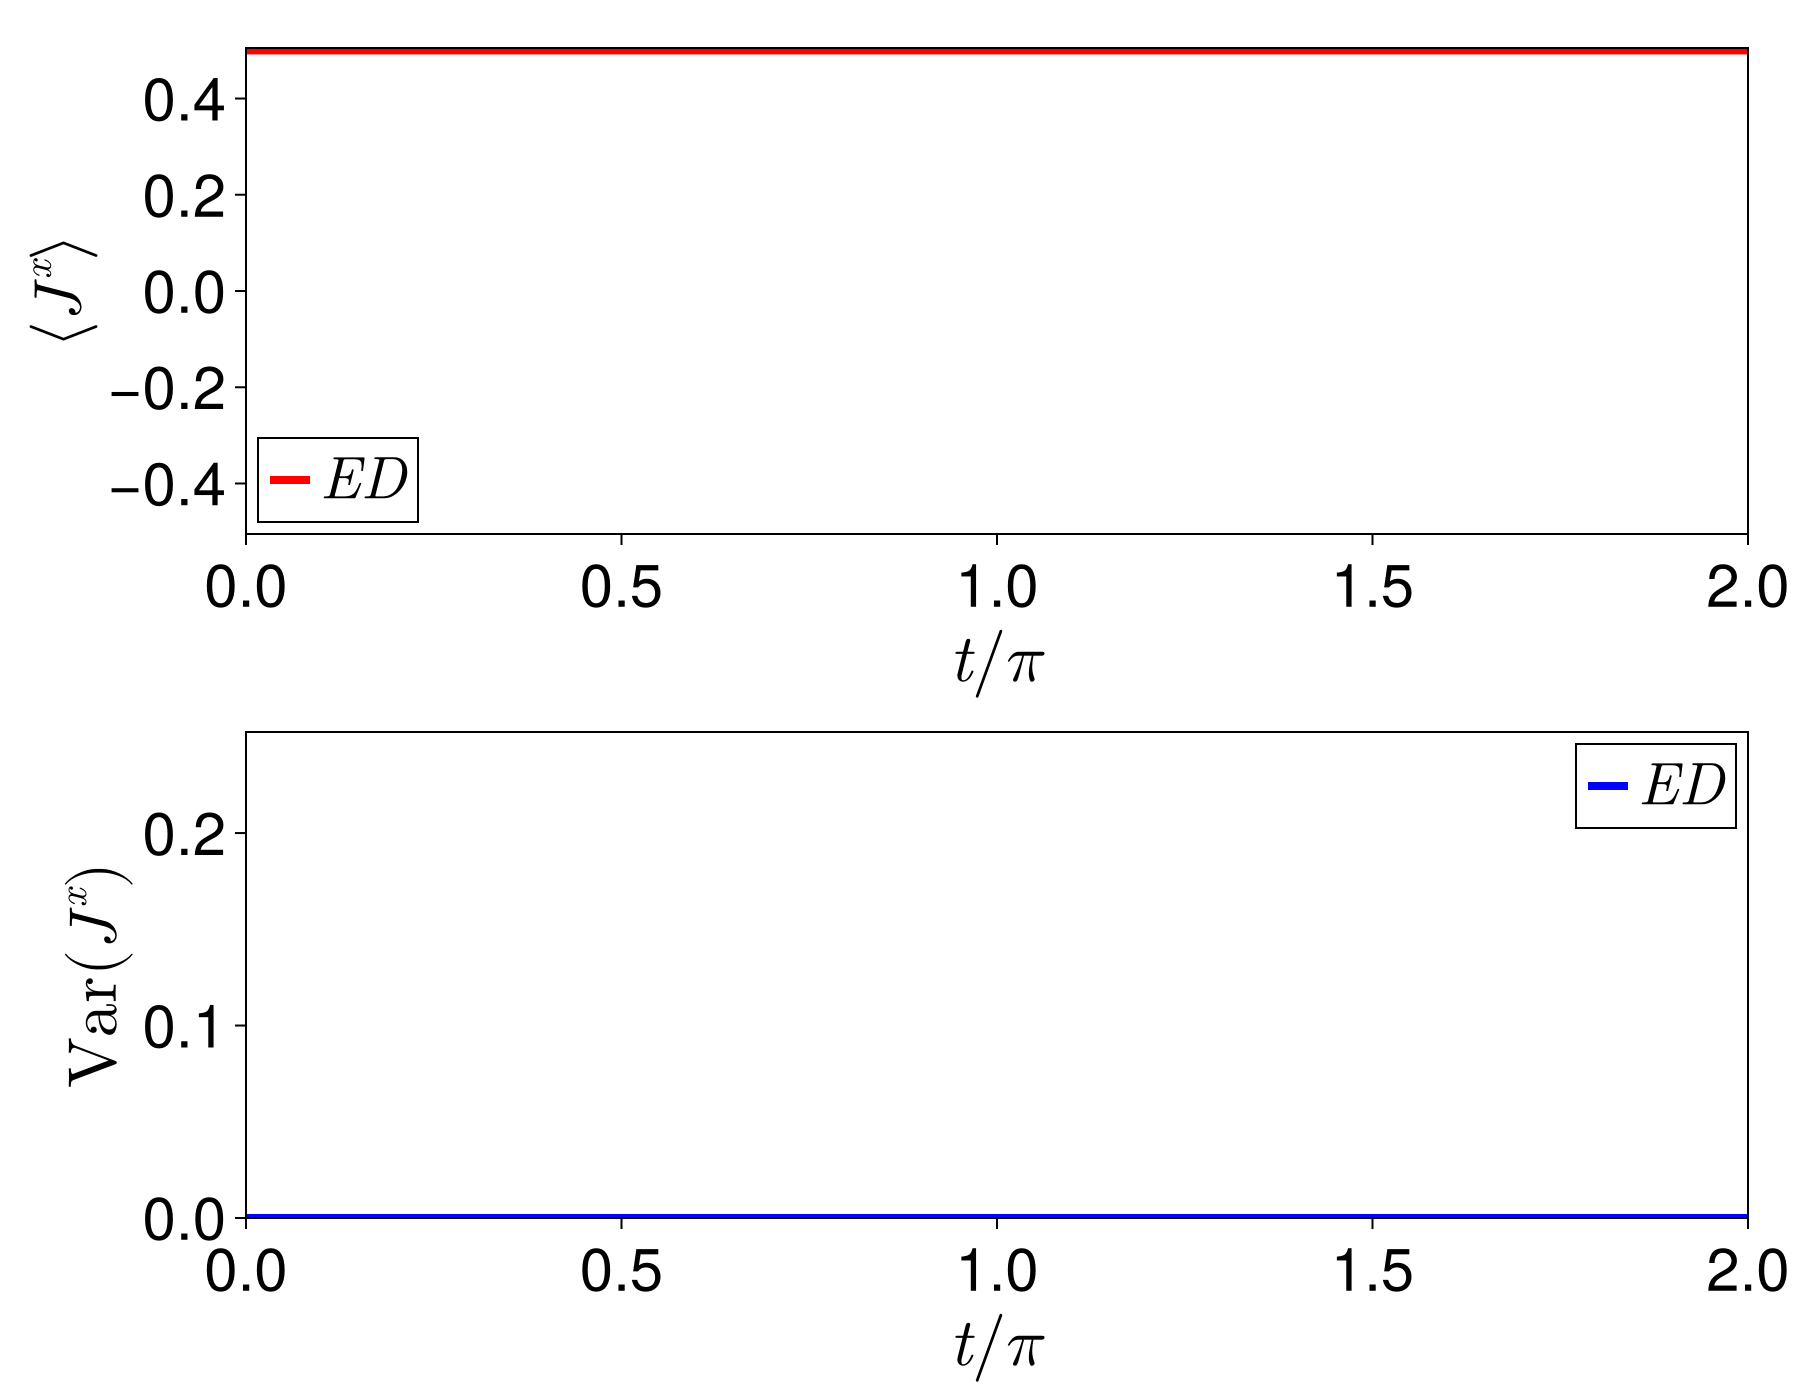

In [37]:
#plotting

f = Figure(font="Helvetica", figure_padding=(10, 26, 10, 24), size=(900, 700), backgroundcolor=:white, fontsize=30, tickfontsize=30)
ax1 = Axis(f[1, 1], xlabel= L"t/\pi", ylabel=L"\langle J^{x} \rangle", xlabelsize=34, ylabelsize=34, xgridvisible = false, ygridvisible = false)
ax2 = Axis(f[2, 1], xlabel= L"t/\pi", ylabel=L"\mathrm{Var} ( J^{x} )", xlabelsize=34, ylabelsize=34, xgridvisible = false, ygridvisible = false)


lines!(ax1, les_t/pi, MeanX; linewidth=4, label=L"ED", color = :red)
lines!(ax2, les_t/pi, VarX; linewidth=4, label=L"ED", color = :blue)

axislegend(ax1, position = :lb)
axislegend(ax2, position = :rt)

limits!(ax1, 0, tmax/pi, -S*1.01, S*1.01)
limits!(ax2, 0, tmax/pi, 0, S*S*1.01)

f1 = current_figure()
#for saving the figure, change path and name
# pathF = "C:/Users/trifa/OneDrive/Documents/papers/Little_cats/Figures"
# name = "C_vs_t_EDvL_unif2D_N$(N)_S$(S)"
# save("$pathF/$name.png", f1)
f1

# Analytical calculations for 2 atoms

## Description for a single atom

In [12]:

#full statistics for a single atom
#Only four states
Adg = 1 #| 1, 0, 0, 0>
Ade = 0 #| 0, 1, 0, 0>
Aug = 0 #| 0, 0, 1, 0>
Aue = 0 #| 0, 0, 0, 1>

#After Bragg BS (pi/2)
Bdg = sqrt(2)/2 #| 1, 0, 0, 0>
Bde = 0 #| 0, 1, 0, 0>
Bug = sqrt(2)/2 #| 0, 0, 1, 0>
Bue = 0 #| 0, 0, 0, 1>

#After Bloch BS (pi/2) + Bloch evol
Cdg = 1/2 #| 1, 0, 0, 0>
Cde = exp(1im*deltad)/2 #| 0, 1, 0, 0>
Cug = 1/2 #| 0, 0, 1, 0>
Cue = exp(1im*deltau)/2 #| 0, 0, 0, 1>

#After second Bloch BS also pi/2, not -pi/2
Ddg = sqrt(2)*(1-exp(1im*deltad))/4 #| 1, 0, 0, 0>
Dde = sqrt(2)*(exp(1im*deltad)+1)/4 #| 0, 1, 0, 0>
Dug = sqrt(2)*(1-exp(1im*deltau))*exp(1im*Dphi)/4 #| 0, 0, 1, 0>
Due = sqrt(2)*(exp(1im*deltau)+1)*exp(1im*Dphi)/4 #| 0, 0, 0, 1>

# #After second Bragg BS -pi/2 (Dphi = 0)
# Edg = (2+exp(1im*deltad)+exp(1im*deltau))/4 #| 1, 0, 0, 0> (sqrt(2)*Ddg + sqrt(2)*Dug)/2
# Ede = (exp(1im*deltad)+ exp(1im*deltau)-2)/4 #| 0, 1, 0, 0> (sqrt(2)*Dde + sqrt(2)*Due)/2
# Eug = (exp(1im*deltad)-exp(1im*deltau))/4 #| 0, 0, 1, 0> (sqrt(2)*Dug - sqrt(2)*Ddg)/2
# Eue = (exp(1im*deltau)-exp(1im*deltad))/4 #| 0, 0, 0, 1> (sqrt(2)*Due - sqrt(2)*Dde)/2

#After second Bragg BS -pi/2 (Dphi != 0)
Edg = (1-exp(1im*deltad)+exp(1im*Dphi)*(1-exp(1im*deltau)))/4 #| 1, 0, 0, 0> (sqrt(2)*Ddg + sqrt(2)*Dug)/2
Ede = (exp(1im*deltad)+1 + exp(1im*Dphi)*(exp(1im*deltau)+1))/4 #| 0, 1, 0, 0> (sqrt(2)*Dde + sqrt(2)*Due)/2
Eug = (exp(1im*Dphi)*(1-exp(1im*deltau))-(1-exp(1im*deltad)))/4 #| 0, 0, 1, 0> (sqrt(2)*Dug - sqrt(2)*Ddg)/2
Eue = (exp(1im*Dphi)*(exp(1im*deltau)+1)-(1+exp(1im*deltad)))/4 #| 0, 0, 0, 1> (sqrt(2)*Due - sqrt(2)*Dde)/2


Psingledg = abs2(Edg) 
Psinglede = abs2(Ede) 
Psingleug = abs2(Eug) 
Psingleue = abs2(Eue)

#formula of Magdalena
PgdM = (1-cos((deltau-deltad)/2)*cos((deltau+deltad)/2) + 2*cos(Dphi + (deltau-deltad)/2)*sin(deltad/2)*sin(deltau/2))/4
PguM = (1-cos((deltau-deltad)/2)*cos((deltau+deltad)/2) - 2*cos(Dphi + (deltau-deltad)/2)*sin(deltad/2)*sin(deltau/2))/4
PgM = (1-cos((deltau-deltad)/2)*cos((deltau+deltad)/2))/2

Psingledg, PgdM, Psingleug, PguM



(0.1908427591413679, 0.19084275914136792, 0.007380545561995194, 0.0073805455619952165)

## Description for two independent atoms

$$
\vert \psi \rangle = \alpha_{2} \vert 2, 0, 0, 0 \rangle + \alpha_{1} \vert 1, 0, 1, 0\rangle + \alpha_{2} \vert 0, 0, 2, 0 \rangle
$$

$$
\vert \psi \rangle = \beta_{2} \vert 2, 0, 0, 0 \rangle + \beta_{1} \vert 1, 1, 0, 0\rangle + \beta_{2} \vert 0, 2, 0, 0 \rangle
$$

In [ ]:
alpha1 = sqrt(2)/2 #to squeeze the external state : alpha1 < sqrt(2)/2
alpha2 = sqrt((1-alpha1^2)/2)

beta1 = sqrt(2)/2 #squeeze the internal state : beta1 < sqrt(2)/2
beta2 = sqrt((1-beta1^2)/2)

norma = alpha1^2 + 2*alpha2^2
normb = beta1^2 + 2*beta2^2
norma, normb

(1.0, 1.0)

In [24]:
#state normalization after 1st Bragg and 1st Bloch BS:

#states in the down branch
A2dg = alpha2*beta2 #for state |2, 0, 0, 0>
A2de = alpha2*beta2 #for state |0, 2, 0, 0>
A1dg1de = alpha2*beta1 #for state |1, 1, 0, 0>


#states in the upper branch
A2ug = alpha2*beta2 #for state |0, 0, 2, 0>
A2ue = alpha2*beta2 #for state |0, 0, 0, 2>
A1ug1ue = alpha2*beta1 #for state |0, 0, 1, 1>

#states both upper and lower:
A1dg1ue = alpha1/2 #for state |1, 0, 0, 1>
A1de1ug = alpha1/2 #for state |0, 1, 1, 0>
A1dg1ug = alpha1/2 #for state |1, 0, 1, 0>
A1de1ue = alpha1/2 #for state |0, 1, 0, 1>



norm =  abs2(A1dg1de) + abs2(A1ug1ue) + abs2(A1dg1ue) + abs2(A1de1ug) + abs2.(A2dg) + abs2(A2ug) + abs2(A1dg1ug) + abs2(A2de) + abs2(A2ue) + abs2(A1de1ue) #full basis but without 0101; 0200 and 0002 

0.9999999999999998

In [25]:
#State normalization after full Bloch evolution
deltad = pi/4 #delta down, phase difference between ground down and excited down
deltau = pi/3 #delta up, phase difference between ground up and excited up
Dphi = pi/20 #global phase difference between up path and down path

#states in the down branch
B2dg = alpha2*beta2 #for state |2, 0, 0, 0>
B2de = alpha2*beta2*exp(1im*2*deltad) #for state |0, 2, 0, 0>
B1dg1de = alpha2*beta1*exp(1im*deltad) #for state |1, 1, 0, 0>

#states in the upper branch
B2ug = alpha2*beta2*exp(1im*2*Dphi) #for state |0, 0, 2, 0>
B2ue = alpha2*beta2*exp(1im*2*deltau)*exp(1im*2*Dphi) #for state |0, 0, 0, 2>
B1ug1ue = alpha2*beta1*exp(1im*deltau)*exp(1im*2*Dphi) #for state |0, 0, 1, 1>

#states both upper and lower:
B1dg1ug = alpha1*exp(1im*Dphi)/2 #for state |1, 0, 1, 0>
B1dg1ue = alpha1*exp(1im*deltau)*exp(1im*Dphi)/2 #for state |1, 0, 0, 1>
B1de1ug = alpha1*exp(1im*deltad)*exp(1im*Dphi)/2 #for state |0, 1, 1, 0>
B1de1ue = alpha1*exp(1im*(deltad+deltau))*exp(1im*Dphi)/2 #for state |0, 1, 0, 1>



norm3 =  abs2(B1dg1de) + abs2(B1ug1ue) + abs2(B1dg1ue) + abs2(B1de1ug) + abs2.(B2dg) + abs2(B2ug) + abs2(B1dg1ug) + abs2(B2de) + abs2(B2ue) + abs2(B1de1ue) #full basis but without 0101; 0200 and 0002

norm3

1.0

In [26]:
# 2nd Bloch BS, also pi/2, not -pi/2 for Magdalena!!!

#1 ground one excited sector*5
C1dg1de = alpha2*beta2*(1 - exp(1im*2*deltad))/sqrt(2)#both in d
C1ug1ue = alpha2*beta2*exp(1im*2*Dphi)*(1- exp(1im*2*deltau))/sqrt(2)#both in u

C1dg1ue = alpha1*exp(1im*Dphi)*(1-exp(1im*deltad))*(1+exp(1im*deltau))/4 #d in g, u in e
C1de1ug = alpha1*exp(1im*Dphi)*(1-exp(1im*deltau))*(1+exp(1im*deltad))/4 #d in e, u in g

#2 spin ground sector
C2dg = alpha2*(beta2*(1+exp(2*1im*deltad)) - sqrt(2)*beta1*exp(1im*deltad))/2
C2ug = alpha2*exp(1im*2*Dphi)*(beta2*(1+exp(2*1im*deltau)) - sqrt(2)*beta1*exp(1im*deltau))/2
C1dg1ug = alpha1*exp(1im*Dphi)*(1-exp(1im*deltad))*(1-exp(1im*deltau))/4

#add C2de, C2ue and C1de1ue
C2de = alpha2*(beta2*(1+exp(2*1im*deltad)) + sqrt(2)*beta1*exp(1im*deltad))/2
C2ue = alpha2*exp(1im*2*Dphi)*(beta2*(1+exp(2*1im*deltau)) + sqrt(2)*beta1*exp(1im*deltau))/2
C1de1ue = alpha1*exp(1im*Dphi)*(exp(1im*deltad)+1)*(exp(1im*deltau)+1)/4


# #1 ground one excited sector
D1dg1de =  sqrt(2)*(B2dg-B2de)/2#both in d
D1ug1ue = sqrt(2)*(B2ug-B2ue)/2#both in u

D1dg1ue = (B1dg1ug + B1dg1ue - B1de1ug - B1de1ue)/2 #d in g, u in e
D1de1ug = (B1dg1ug - B1dg1ue + B1de1ug - B1de1ue)/2 #d in e, u in g

#2 spin ground sector
D2dg = (B2dg - sqrt(2)*B1dg1de + B2de)/2
D2ug = (B2ug - sqrt(2)*B1ug1ue + B2ue)/2
D1dg1ug = (B1dg1ug - B1dg1ue - B1de1ug + B1de1ue)/2

#2 excited spin sector
D2de = (B2dg + sqrt(2)*B1dg1de + B2de)/2
D2ue = (B2ug + sqrt(2)*B1ug1ue + B2ue)/2
D1de1ue = (B1dg1ug + B1dg1ue + B1de1ug + B1de1ue)/2


#check normalization after 2nd Bloch BS (recombination)
normC1 = abs2(C1dg1de) + abs2(C1ug1ue) + abs2(C1dg1ue) + abs2(C1de1ug) + abs2.(C2dg) + abs2(C2ug) + abs2(C1dg1ug) #full basis but without 0101; 0200 and 0002 
normC3 =  abs2(C1dg1de) + abs2(C1ug1ue) + abs2(C1dg1ue) + abs2(C1de1ug) + abs2.(C2dg) + abs2(C2ug) + abs2(C1dg1ug) + abs2(C2de) + abs2(C2ue) + abs2(C1de1ue) #full basis but without 0101; 0200 and 0002

# normD1 = abs2(D1dg1de) + abs2(D1ug1ue) + abs2(D1dg1ue) + abs2(D1de1ug) + abs2.(D2dg) + abs2(D2ug) + abs2(D1dg1ug) #full basis but without 0101; 0200 and 0002 
# normD3 =  abs2(D1dg1de) + abs2(D1ug1ue) + abs2(D1dg1ue) + abs2(D1de1ug) + abs2.(D2dg) + abs2(D2ug) + abs2(D1dg1ug) + abs2(D2de) + abs2(D2ue) + abs2(D1de1ue) #full basis but without 0101; 0200 and 0002 

(normC1, normC3)

(0.3571005143556869, 0.9999999999999999)

In [27]:
#check C = D

(abs2.(C1dg1de-D1dg1de), abs2.(C1ug1ue-D1ug1ue), abs2.(C1dg1ue-D1dg1ue), abs2.(C1de1ug-D1de1ug) )
# (abs2.(C2dg-D2dg), abs2.(C2ug-D2ug), abs2.(C1dg1ug-D1dg1ug))
# (abs2.(C2de-D2de), abs2.(C2ue-D2ue), abs2.(C1de1ue-D1de1ue))
#check ok

(3.0814879110195774e-33, 3.851859888774472e-33, 1.5407439555097887e-33, 0.0)

In [28]:
#State normalizaition after 2nd Bragg BS

# one ground one excited sector
E1dg1de =  (D1dg1de + D1dg1ue + D1de1ug + D1ug1ue)/2#both in d
E1ug1ue = (D1dg1de - D1dg1ue - D1de1ug + D1ug1ue)/2#both in u

E1dg1ue = (-D1dg1de + D1dg1ue - D1de1ug + D1ug1ue)/2 #d in g, u in e
E1de1ug = (-D1dg1de - D1dg1ue + D1de1ug + D1ug1ue)/2 #d in e, u in g

#2 spin ground sector
E2dg = (D2dg + sqrt(2)*D1dg1ug + D2ug)/2
E2ug = (D2dg - sqrt(2)*D1dg1ug + D2ug)/2
E1dg1ug = sqrt(2)*(D2ug-D2dg)/2

#2 excited spin sector
E2de = (D2de + sqrt(2)*D1de1ue + D2ue)/2
E2ue = (D2de - sqrt(2)*D1de1ue + D2ue)/2
E1de1ue = sqrt(2)*(D2ue-D2de)/2

norm3 =  abs2(E1dg1de) + abs2(E1ug1ue) + abs2(E1dg1ue) + abs2(E1de1ug) + abs2.(E2dg) + abs2(E2ug) + abs2(E1dg1ug) + abs2(E2de) + abs2(E2ue) + abs2(E1de1ue) #full basis but without 0101; 0200 and 0002

norm3

1.0

The partial trace does not change the overall probability, nor its variance, but it changes the data structure: from a wavevector for the 4 modes to a densoty matrix for the two ground modes.
We need to decide which structure is most efficient numerically to compute Pgu and Pgd.

In [29]:
#full statistics of number of atoms in ground
Pgd = (2*abs2(E2dg) + abs2(E1dg1ug) + abs2(E1dg1de) + abs2(E1dg1ue))/2
Pgu = (2*abs2(E2ug) + abs2(E1dg1ug) + abs2(E1ug1ue) + abs2(E1de1ug))/2
Pg = Pgd+Pgu

Ped = (2*abs2(E2de) + abs2(E1de1ue) + abs2(E1dg1de) + abs2(E1de1ug))/2
Peu = (2*abs2(E2ue) + abs2(E1de1ue) + abs2(E1ug1ue) + abs2(E1dg1ue))/2
Pe = Ped+Peu

#formula of Magdalena
PgdM = (1-cos((deltau-deltad)/2)*cos((deltau+deltad)/2) + 2*cos(Dphi + (deltau-deltad)/2)*sin(deltad/2)*sin(deltau/2))/4
PguM = (1-cos((deltau-deltad)/2)*cos((deltau+deltad)/2) - 2*cos(Dphi + (deltau-deltad)/2)*sin(deltad/2)*sin(deltau/2))/4
PgM = (1-cos((deltau-deltad)/2)*cos((deltau+deltad)/2))/2

#check the equality
PgdM, Pgd, PguM, Pgu, Pg+Pe

(0.19084275914136792, 0.19082441108502077, 0.0073805455619952165, 0.007398893618342276, 0.9999999999999999)

In [30]:
#variance of number of atoms in ground
#compare this from binomial distribution with p, (1-p)!

VarPgd = (4*abs2(E2dg) + abs2(E1dg1ug) + abs2(E1dg1de) + abs2(E1dg1ue))/4 - Pgd^2
VarPgu = (4*abs2(E2ug) + abs2(E1dg1ug) + abs2(E1ug1ue) + abs2(E1de1ug))/4 - Pgu^2
VarPg = (4*abs2(E2dg) + 4*abs2(E2ug) + 4*abs2(E1dg1ug) + abs2(E1dg1de) + abs2(E1dg1ue) + abs2(E1ug1ue) + abs2(E1de1ug))/4-Pg^2

VarPgd, VarPgu, VarPg

(0.07720622942281749, 0.0036730768090629438, 0.0794922213496788)

In [22]:
#with binomial:
p = Psingledg
Varsingledg = (4*p*p+2*p*(1-p))/4-p^2
Varsingledg, VarPgd #comparison ok

(0.07721090021233887, 0.06368836768826838)

## Squeezing  for 2 atoms

From the results below, Pg seems to depend on beta, why is that?
Check this results by computing the explicit form of coefficients for E

In [31]:
#squeezing for internal state with beta1

deltad = pi/4 #delta down, phase difference between ground down and excited down
deltau = pi/3 #delta up, phase difference between ground up and excited up
Dphi = pi/20 #global phase difference between up path and down path

alpha1 = sqrt(2)/2 #to squeeze the external state : alpha1 < sqrt(2)/2
alpha2 = sqrt((1-alpha1^2)/2)

nb = 101
les_beta1 = range(0, 1, nb)

lesPgd = zeros(Float64, nb)
lesPgu = zeros(Float64, nb)
lesPg = zeros(Float64, nb)
lesVarPgd = zeros(Float64, nb)
lesVarPgu = zeros(Float64, nb)
lesVarPg = zeros(Float64, nb)

for kb in 1:nb

    beta1 = les_beta1[kb] #squeeze the internal state : beta1 < sqrt(2)/2
    beta2 = sqrt((1-beta1^2)/2)


    #state after full Bloch evolution and BS
    #1 ground one excited sector
    C1dg1de = alpha2*beta2*(1 - exp(1im*2*deltad))/sqrt(2)#both in d
    C1ug1ue = alpha2*beta2*exp(1im*2*Dphi)*(1- exp(1im*2*deltau))/sqrt(2)#both in u

    C1dg1ue = alpha1*exp(1im*Dphi)*(1-exp(1im*deltad))*(1+exp(1im*deltau))/4 #d in g, u in e
    C1de1ug = alpha1*exp(1im*Dphi)*(1-exp(1im*deltau))*(1+exp(1im*deltad))/4 #d in e, u in g

    #2 spin ground sector
    C2dg = alpha2*(beta2*(1+exp(2*1im*deltad)) - sqrt(2)*beta1*exp(1im*deltad))/2
    C2ug = alpha2*exp(1im*2*Dphi)*(beta2*(1+exp(2*1im*deltau)) - sqrt(2)*beta1*exp(1im*deltau))/2
    C1dg1ug = alpha1*exp(1im*Dphi)*(1-exp(1im*deltad))*(1-exp(1im*deltau))/4

    #add C2de, C2ue and C1de1ue
    C2de = alpha2*(beta2*(1+exp(2*1im*deltad)) + sqrt(2)*beta1*exp(1im*deltad))/2
    C2ue = alpha2*exp(1im*2*Dphi)*(beta2*(1+exp(2*1im*deltau)) + sqrt(2)*beta1*exp(1im*deltau))/2
    C1de1ue = alpha1*exp(1im*Dphi)*(exp(1im*deltad)+1)*(exp(1im*deltau)+1)/4

    #state after full evolution
    # one ground one excited sector
    E1dg1de =  (C1dg1de + C1dg1ue + C1de1ug + C1ug1ue)/2# |1, 1, 0, 0>
    E1ug1ue = (C1dg1de - C1dg1ue - C1de1ug + C1ug1ue)/2# |0, 0, 1, 1>

    E1dg1ue = (-C1dg1de + C1dg1ue - C1de1ug + C1ug1ue)/2 #|1, 0, 0, 1>
    E1de1ug = (-C1dg1de - C1dg1ue + C1de1ug + C1ug1ue)/2 #|0, 1, 1, 0>

    #2 spin ground sector
    E2dg = (C2dg + sqrt(2)*C1dg1ug + C2ug)/2 #|2, 0, 0, 0>
    E2ug = (C2dg - sqrt(2)*C1dg1ug + C2ug)/2 #|0, 0, 2, 0>
    E1dg1ug = sqrt(2)*(C2ug-C2dg)/2 #|1, 0, 1, 0>

    # #2 excited spin sector
    # E2de = (C2de + sqrt(2)*C1de1ue + C2ue)/2 #|0, 2, 0, 0>
    # E2ue = (C2de - sqrt(2)*C1de1ue + C2ue)/2 #|0, 0, 0, 2>
    # E1de1ue = sqrt(2)*(C2ue-C2de)/2 #|0, 1, 0, 1>

    #probability and variance
    Pgd = (2*abs2(E2dg) + abs2(E1dg1ug) + abs2(E1dg1de) + abs2(E1dg1ue))/2
    Pgu = (2*abs2(E2ug) + abs2(E1dg1ug) + abs2(E1ug1ue) + abs2(E1de1ug))/2
    Pg = Pgd+Pgu

    VarPgd = (4*abs2(E2dg) + abs2(E1dg1ug) + abs2(E1dg1de) + abs2(E1dg1ue))/4 - Pgd^2
    VarPgu = (4*abs2(E2ug) + abs2(E1dg1ug) + abs2(E1ug1ue) + abs2(E1de1ug))/4 - Pgu^2
    VarPg = (4*abs2(E2dg) + 4*abs2(E2ug) + 4*abs2(E1dg1ug) + abs2(E1dg1de) + abs2(E1dg1ue) + abs2(E1ug1ue) + abs2(E1de1ug))/4-Pg^2

    lesPgd[kb] = Pgd
    lesPgu[kb] = Pgu
    lesPg[kb] = Pg

    lesVarPgd[kb] = VarPgd
    lesVarPgu[kb] = VarPgu
    lesVarPg[kb] = VarPg
end

    

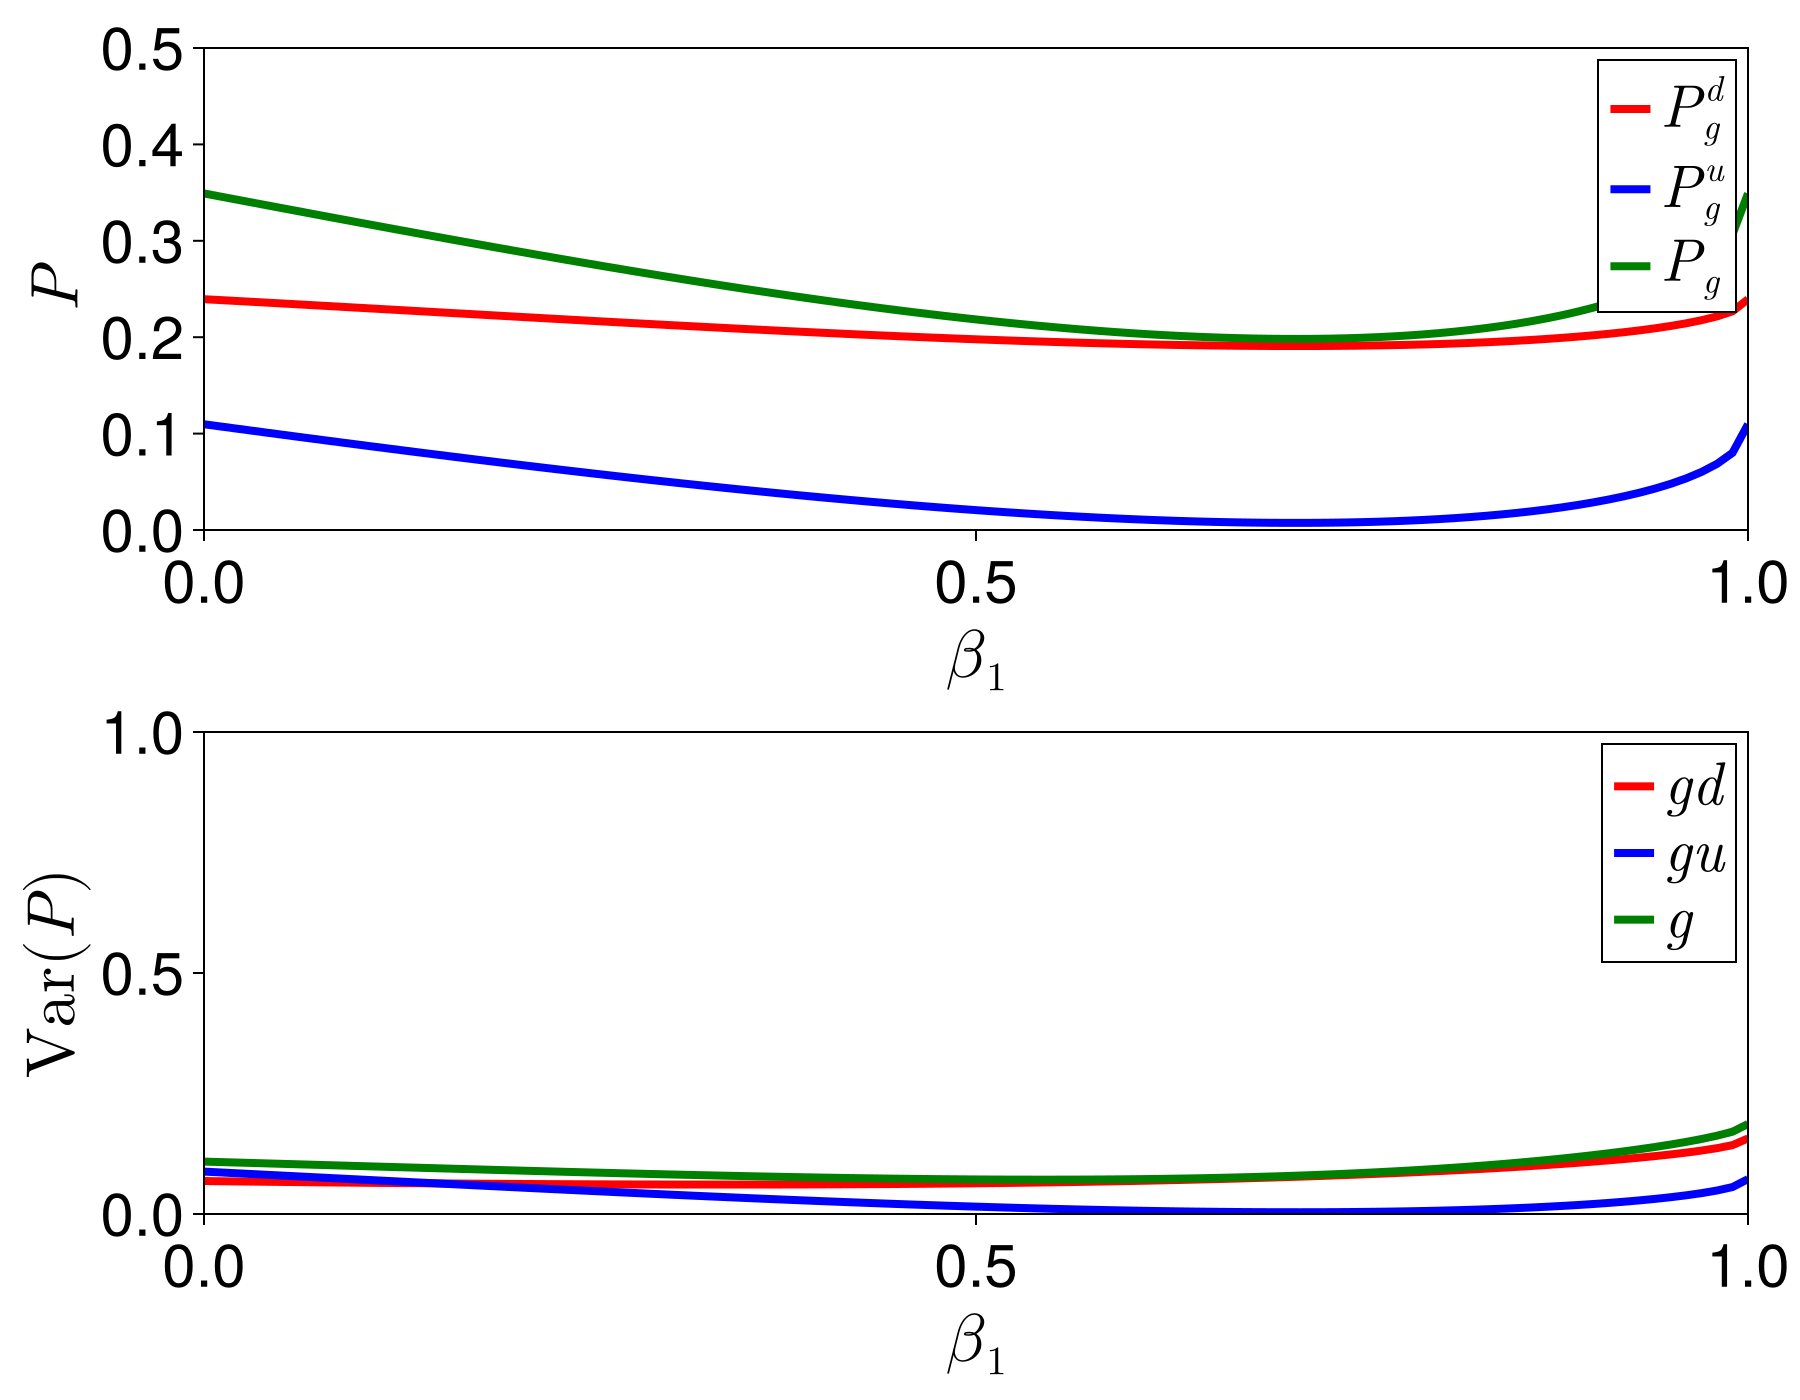

In [35]:
#plot the results

f = Figure(font="Helvetica", figure_padding=(10, 26, 10, 24), size=(900, 700), backgroundcolor=:white, fontsize=30, tickfontsize=30)
ax1 = Axis(f[1, 1], xlabel= L"\beta_1", ylabel=L"P", xlabelsize=34, ylabelsize=34, xgridvisible = false, ygridvisible = false)
ax2 = Axis(f[2, 1], xlabel= L"\beta_1", ylabel=L"\mathrm{Var} ( P )", xlabelsize=34, ylabelsize=34, xgridvisible = false, ygridvisible = false)


lines!(ax1, les_beta1, lesPgd; linewidth=4, label=L"P_{g}^{d}", color = :red)
lines!(ax1, les_beta1, lesPgu; linewidth=4, label=L"P_{g}^{u}", color = :blue)
lines!(ax1, les_beta1, lesPg; linewidth=4, label=L"P_{g}", color = :green)
lines!(ax2, les_beta1, lesVarPgd; linewidth=4, label=L"gd", color = :red)
lines!(ax2, les_beta1, lesVarPgu; linewidth=4, label=L"gu", color = :blue)
lines!(ax2, les_beta1, lesVarPg; linewidth=4, label=L"g", color = :green)

axislegend(ax1, position = :rt)
axislegend(ax2, position = :rt)

limits!(ax1, 0, 1, 0, 0.5)
limits!(ax2, 0, 1, 0, 1)

f1 = current_figure()
#for saving the figure, change path and name
# pathF = "C:/Users/trifa/OneDrive/Documents/papers/Little_cats/Figures"
# name = "C_vs_t_EDvL_unif2D_N$(N)_S$(S)"
# save("$pathF/$name.png", f1)
f1